# 4. Zeuthen, and a small tournament

**Examples of:**

- the **Zeuthen strategy**: the agent with the most to lose in a conflict concedes;
- why this protocol ends at the **Nash solution**;
- how the strategies of the previous chapters compare when the negotiation may break down.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from carpool import *

## 4.1 Who should concede?

Each agent computes its **risk**: the share of its gain it would lose by accepting the other's offer,
$$\text{risk}_i = \frac{U_i(\text{my offer}) - U_i(\text{other's offer})}{U_i(\text{my offer})}$$
The agent with the **smaller** risk has the most to lose in a conflict: it concedes.

With $U_{Alice}(p) = p - 4$ and $U_{Bob}(p) = 18 - p$.

**Exercise 1**.  
- Write two functions `risk_alice(a, b)` and `risk_bob(a, b)` (Alice asks $a$, Bob offers $b$). 
- Check the example of the slide: Alice asks 16 EUR, Bob offers 8 EUR. 
- Who concedes?

In [2]:
# Exercise 1: your code here

Alice: risk 0.67 | Bob: risk 0.80


**Reading.** Alice's risk is 0.67, Bob's 0.80: Alice has more to lose, **she concedes**.

## 4.2 The Monotonic Concession Protocol

Start with Alice at 18 EUR and Bob at 4 EUR. At each step, the agent with the smaller risk concedes **0.5 EUR** (both concede if the risks are equal). Stop when the offers meet.

**Exercise 2** *(≈ 10 lines)*. Write this loop, keep the history of the offers, and plot it. Where do they meet?

In [4]:
# Exercise 2: your code here

the offers meet at [11. 11.]


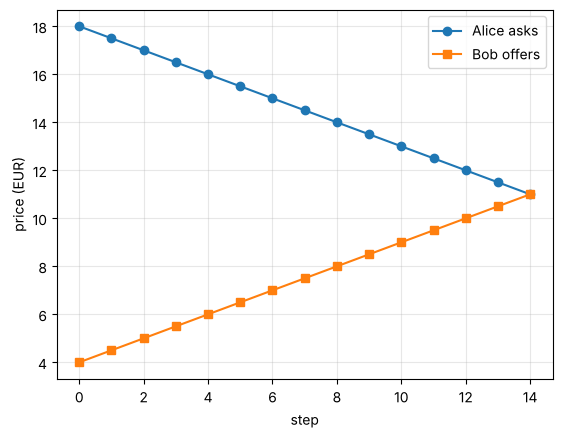

In [5]:
def zeuthen(u_alice, u_bob, step=0.5):
    a, b = 18.0, 4.0
    history = [(a, b)]
    while a > b:
        ra = (u_alice(a) - u_alice(b)) / u_alice(a)
        rb = (u_bob(b) - u_bob(a)) / u_bob(b)
        if ra <= rb:
            a -= step
        if rb <= ra:
            b += step
        history.append((a, b))
    return np.array(history)

h = zeuthen(u_alice, u_bob)
print("the offers meet at", h[-1])
plt.plot(h[:, 0], "o-", label="Alice asks"); plt.plot(h[:, 1], "s-", label="Bob offers")
plt.xlabel("step"); plt.ylabel("price (EUR)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Reading.** The agents concede in turn and meet at **11 EUR**: the Nash solution (Harsanyi, 1956). Nobody computed it: it comes out of the rule "the one with the most to lose concedes".

**Exercise 3** *(≈ 6 lines)*. Now Bob is **risk-averse**: $U_{Bob}(p) = \sqrt{18 - p}$. Run the protocol again. Compare with the Nash solution computed directly: the price that maximises $(p - 4)\sqrt{18 - p}$.

In [6]:
# Exercise 3: your code here

In [7]:
u_bob_averse = lambda p: np.sqrt(max(18 - p, 0))
h = zeuthen(u_alice, u_bob_averse)
prices = np.linspace(4, 18, 1401)
nash = prices[np.argmax((prices - 4) * np.sqrt(18 - prices))]
print(f"Zeuthen: {h[-1][0]:.2f} EUR | Nash: {nash:.2f} EUR")

Zeuthen: 13.50 EUR | Nash: 13.33 EUR


**Reading.** Both give about **13.3 to 13.5 EUR** (Zeuthen moves by steps of 0.5 EUR): the risk-averse Bob fears a conflict more, concedes more often and pays more. Zeuthen still ends at the Nash solution, computed with Bob's utility.

## 4.3 A small tournament

Which strategy is the best? It depends on the opponent... and on the risk of breakdown.

**Exercise 4** *(explore, ≈ 15 lines)*. Build a dictionary of strategies for Alice and the same for Bob: Boulware ($\beta = 0.3$), linear, Conceder ($\beta = 3$), Tit-for-Tat, Distance ($k = 0.2$). Make every Alice negotiate with every Bob, 500 times with `risk=0.1`. Show Alice's mean gain for each pair, and her mean gain over all the Bobs. Which Alice is the best on average? Try again with `risk=0`.

In [8]:
# Exercise 4: your code here

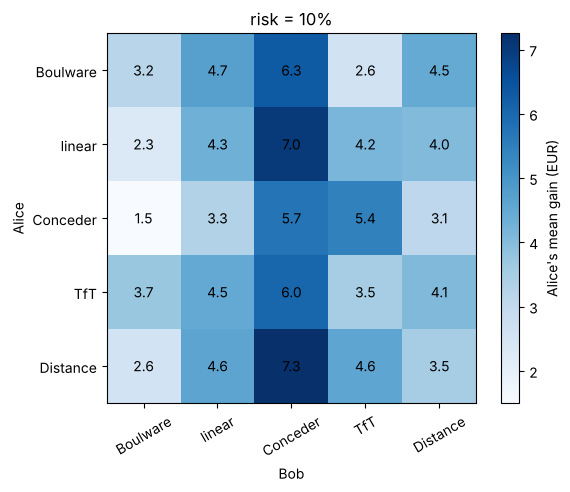

risk = 10%, Alice's mean gain over all Bobs: {'Boulware': 4.25, 'linear': 4.37, 'Conceder': 3.81, 'TfT': 4.37, 'Distance': 4.5}


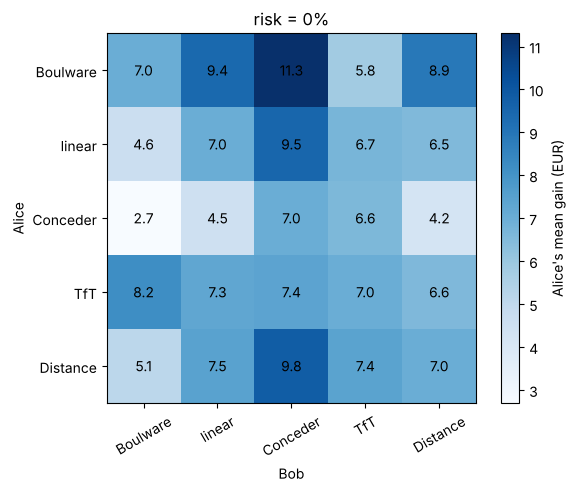

risk = 0%, Alice's mean gain over all Bobs: {'Boulware': 8.48, 'linear': 6.87, 'Conceder': 5.0, 'TfT': 7.28, 'Distance': 7.36}


In [9]:
alices = {
    "Boulware": lambda r, T, m, o: time_dependent(r, T, 18, 4, 0.3),
    "linear": lambda r, T, m, o: time_dependent(r, T, 18, 4, 1),
    "Conceder": lambda r, T, m, o: time_dependent(r, T, 18, 4, 3),
    "TfT": lambda r, T, m, o: tit_for_tat(m, o, 18, -1),
    "Distance": lambda r, T, m, o: distance(m, o, 18, 0.2),
}
bobs = {
    "Boulware": lambda r, T, m, o: time_dependent(r, T, 4, 18, 0.3),
    "linear": lambda r, T, m, o: time_dependent(r, T, 4, 18, 1),
    "Conceder": lambda r, T, m, o: time_dependent(r, T, 4, 18, 3),
    "TfT": lambda r, T, m, o: tit_for_tat(m, o, 4, +1),
    "Distance": lambda r, T, m, o: distance(m, o, 4, 0.2),
}
for risk in (0.1, 0.0):
    table = np.array([[np.mean([negotiate(a, b, risk=risk, seed=i)["gains"][0] for i in range(500 if risk else 1)])
                       for b in bobs.values()] for a in alices.values()])
    plt.imshow(table, cmap="Blues"); plt.colorbar(label="Alice's mean gain (EUR)")
    plt.xticks(range(5), bobs, rotation=30); plt.yticks(range(5), alices)
    plt.xlabel("Bob"); plt.ylabel("Alice"); plt.title(f"risk = {risk:.0%}")
    for i in range(5):
        for j in range(5):
            plt.text(j, i, f"{table[i, j]:.1f}", ha="center", va="center")
    plt.show()
    print(f"risk = {risk:.0%}, Alice's mean gain over all Bobs:", {k: float(v) for k, v in zip(alices, table.mean(axis=1).round(2))})

**Reading.** There is no strategy that is always the best: each one wins against some opponents and loses against others. Without risk, the Boulware Alice is the best on average (conceding late is free). With a 10 % risk of breakdown, she falls behind Distance, Tit-for-Tat and the linear agent: agents that keep the negotiation moving do better on average. An agent must balance **what it gains by waiting** against **the risk of losing the deal**: the same trade-off as the patience $\delta$ of Rubinstein's model.

## Key points

| Strategy | Game theory |
|---|---|
| Boulware | patient agent: wins more, risks no deal |
| Conceder | impatient agent: safe, leaves surplus |
| Tit-for-Tat | reciprocity (Axelrod) |
| Distance | conceding fast costs |
| Zeuthen | the one with most to lose concedes $\Rightarrow$ Nash solution |